## XOR 학습 다층신경망(3층)

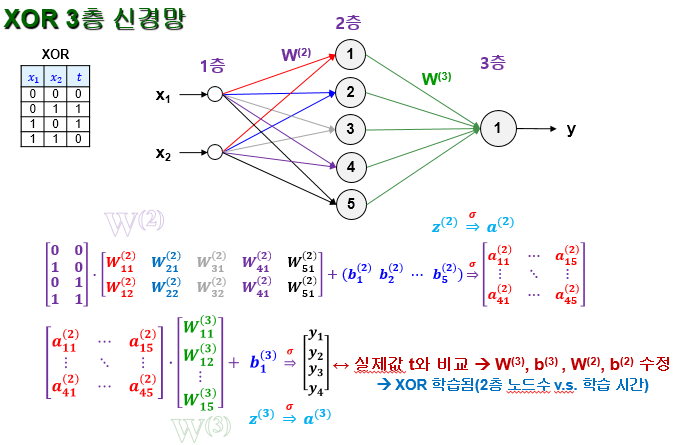

# 행렬, 선형변환
- 입력이 가중치 행렬을 통과하는 것과 가중치 행렬이 입력을 변환하는 것은 같은 결과를 도출할 수 있음
- $X \cdot W = (W^T \cdot X^T)^T$

$$
\underbrace{
\begin{pmatrix}
  0 & 0 \\
  0 & 1 \\
  1 & 0 \\
  1 & 1
\end{pmatrix}
}_{X\;(4\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  w_{11} & w_{12} & w_{13} & w_{14} & w_{15} \\
  w_{21} & w_{22} & w_{23} & w_{24} & w_{25}
\end{pmatrix}
}_{W\;(2\times5)}
=
\left(
\underbrace{
\begin{pmatrix}
  w_{11} & w_{21} \\
  w_{12} & w_{22} \\
  w_{13} & w_{23} \\
  w_{14} & w_{24} \\
  w_{15} & w_{25}
\end{pmatrix}
}_{W^T\;(5\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  0 & 0 & 1 & 1 \\
  0 & 1 & 0 & 1
\end{pmatrix}
}_{X^T\;(2\times4)}
\right)^T
$$

In [ ]:
import numpy as np
M = np.array([[0,1],
              [1,0]])
org = np.array([1,2])

res = np.dot(M, org.T)
print(res)
res = np.dot(org, M.T)
print(res)

[2 1]
[2 1]


In [ ]:
import numpy as np
from datetime import datetime      # datetime.now() 를 이용하여 학습 경과 시간 측정

def sigmoid(x):         # sigmoid 함수
    return 1 / (1+np.exp(-x))

def cross_entropy(t, y) :
    delta = 1e-7    # log 무한대 발산 방지
    return -np.sum(t*np.log(y+delta) + (1-t)*np.log((1-y)+delta))

def numerical_derivative(f, x):      # 수치미분 함수
    delta_x = 1e-4 # 0.0001
    grad = np.zeros_like(x)

    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + delta_x
        fx1 = f(x) # f(x+delta_x)

        x[idx] = tmp_val - delta_x
        fx2 = f(x) # f(x-delta_x)
        grad[idx] = (fx1 - fx2) / (2*delta_x)

        x[idx] = tmp_val
        it.iternext()
    return grad

class LogicGate:
    def __init__(self, gate_name, xdata, tdata, hidden=5):
        self.name = gate_name
        # 입력 데이터, 정답 데이터 초기화
        rows, cols = len(xdata), len(xdata[0])
        self.xdata = xdata.reshape(rows,cols)  # 4개의 입력데이터 x1, x2 에 대하여 batch 처리 행렬
        self.tdata = tdata.reshape(rows,1)  # 4개의 입력데이터 x1, x2 에 대한 각각의 계산 값 행렬

        # 2층 hidden layer unit : 5개 가정,  가중치 W2, 바이어스 b2 초기화
        self.W2 = np.random.rand(cols,hidden)  # weight, 2 X 5 matrix
        self.b2 = np.random.rand(hidden)

        # 3층 output layer unit : 1 개 , 가중치 W3, 바이어스 b3 초기화
        self.W3 = np.random.rand(hidden,1)
        self.b3 = np.random.rand(1)

        # 학습률 learning rate 초기화
        self.lr = 1e-2
        print(self.name + " object is created")

    def feed_forward(self):        # errFunc()함수 대신 feed forward를 통하여 손실함수(cross-entropy) 값 계산
        z2 = np.dot(self.xdata, self.W2) + self.b2  # 은닉층의 선형회귀 값
        a2 = sigmoid(z2)                            # 은닉층의 출력
        z3 = np.dot(a2, self.W3) + self.b3          # 출력층의 선형회귀 값
        y = a3 = sigmoid(z3)                        # 출력층의 출력
        return cross_entropy(self.tdata, y)         # 출력의 손실값 리턴

    def errValue(self):             # 외부 출력을 위한 손실함수(cross-entropy) 값 계산
        return  self.feed_forward()

    def train(self, repeat=8000, outStep=1000):            # 수치미분을 이용하여 손실함수가 최소가 될때 까지 학습하는 함수
        f = lambda x : self.feed_forward()
        start = datetime.now()
        for step in range(repeat+1):
            self.W2 -= self.lr * numerical_derivative(f, self.W2)
            self.b2 -= self.lr * numerical_derivative(f, self.b2)
            self.W3 -= self.lr * numerical_derivative(f, self.W3)
            self.b3 -= self.lr * numerical_derivative(f, self.b3)
            if (step % outStep == 0):
                print("Step = {:<5d}\tError Val = {:.4f}".format(step, self.errValue()))
        print("Training time = ", datetime.now() - start)

    def predict(self, test):      # query, 즉 미래 값 예측 함수
        z2 = np.dot(test, self.W2) + self.b2         # 은닉층의 선형회귀 값
        a2 = sigmoid(z2)                             # 은닉층의 출력
        z3 = np.dot(a2, self.W3) + self.b3           # 출력층의 선형회귀 값
        y = a3 = sigmoid(z3)                         # 출력층의 출력
        return y

In [ ]:
# XOR Gate 객체 생성
xdata = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
tdata = np.array([0, 1, 1, 0])

XOR = LogicGate("XOR", xdata, tdata)
XOR.train(repeat=15000)

XOR object is created
Step = 0    	Error Val = 4.0624
Step = 1000 	Error Val = 2.7688
Step = 2000 	Error Val = 2.7632
Step = 3000 	Error Val = 2.7527
Step = 4000 	Error Val = 2.7292
Step = 5000 	Error Val = 2.6760
Step = 6000 	Error Val = 2.5671
Step = 7000 	Error Val = 2.3798
Step = 8000 	Error Val = 2.1155
Step = 9000 	Error Val = 1.7761
Step = 10000	Error Val = 1.3707
Step = 11000	Error Val = 0.9890
Step = 12000	Error Val = 0.7006
Step = 13000	Error Val = 0.5043
Step = 14000	Error Val = 0.3734
Step = 15000	Error Val = 0.2852
Training time =  0:00:32.677351


In [ ]:
print("===", XOR.name, "testing ... ")
test_data = np.array([ [0, 0], [0, 1], [1, 0], [1, 1], [0.7, 0.3], [0.4,0.6] ])
for test in test_data:
    y = XOR.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== XOR testing ... 
[0. 0.]  =  0  [0.0319]
[0. 1.]  =  1  [0.9081]
[1. 0.]  =  1  [0.9543]
[1. 1.]  =  0  [0.1039]
[0.7 0.3]  =  1  [0.8840]
[0.4 0.6]  =  1  [0.8533]


In [ ]:
# XOR 3-in gate
xdata = np.array([ [0,0,0], [0,0,1], [0,1,0], [0,1,1],[1,0,0], [1,0,1], [1,1,0], [1,1,1] ])
tdata = np.array([0, 1, 1, 0, 1, 0, 0, 1])

XOR3 = LogicGate("XOR_3-in_GATE", xdata, tdata, hidden = 16)
XOR3.train(repeat=15000, outStep=1000)

XOR_3-in_GATE object is created
Step = 0    	Error Val = 31.2239
Step = 1000 	Error Val = 5.5456
Step = 2000 	Error Val = 5.5441
Step = 3000 	Error Val = 5.5429
Step = 4000 	Error Val = 5.5417
Step = 5000 	Error Val = 5.5403
Step = 6000 	Error Val = 5.5385
Step = 7000 	Error Val = 5.5359
Step = 8000 	Error Val = 5.5320
Step = 9000 	Error Val = 5.5252
Step = 10000	Error Val = 5.5123
Step = 11000	Error Val = 5.4836
Step = 12000	Error Val = 5.4080
Step = 13000	Error Val = 5.1814
Step = 14000	Error Val = 4.5612
Step = 15000	Error Val = 3.3946
Training time =  0:02:00.426661


In [ ]:
print("===", XOR3.name, "testing ... ")
test_data = np.array([ [0,0,0], [0,0,1], [0,1,0], [0,1,1],[1,0,0], [1,0,1], [1,1,0], [1,1,1] ])
for test in test_data:
    y = XOR3.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== XOR_3-in_GATE testing ... 
[0 0 0]  =  0  [0.4087]
[0 0 1]  =  1  [0.7249]
[0 1 0]  =  1  [0.7371]
[0 1 1]  =  0  [0.3193]
[1 0 0]  =  1  [0.7365]
[1 0 1]  =  0  [0.3221]
[1 1 0]  =  0  [0.3306]
[1 1 1]  =  0  [0.4668]
